In [1]:
import os, sys
import numpy as np
import pickle
import uproot
import glob
import pandas as pd
from tqdm import tqdm
import json
import ROOT as rt
import fnmatch

## user define
sys.path.append('.')
sys.path.append('./Utils')
from Plotter import HistStack

from beeps import *

Welcome to JupyROOT 6.26/08


# Set config

In [2]:
# ERA="ee17"
# ERA="ee16pre"
# # ERA="mm18"
# ERA="em18"
# # DATE = '20230129_17_eleffmva'
# DATE = '20230301_18'
# # DATE = '20230130_18_dyhighworctight'
# # INPUTDIR = "/eos/user/h/hkwon/Run2/20230130_18_dyhighworctight/mm/"
# INPUTDIR = "/eos/user/h/hkwon/Run2/20230301_18/em/"
import sys
ERA = sys.argv[1]
DATE = sys.argv[2]
INPUTDIR = sys.argv[3]

DUMP_PKL = True
DRAW_SR = True
RUN_SIDEBAND_MET = True
RUN_SIDEBAND_MASS = True
RUN_SIDEBAND_PT = True
DUMP_SIDEBAND_MET_PKL = True
DUMP_SIDEBAND_MASS_PKL = True
DUMP_SIDEBAND_PT_PKL = True
RUN_BTAG = False
EXPORT_VARIABLE = False

# # for dev
# ERA="ee16pre"
# DATE = '20230430wp80_16pre'
# INPUTDIR = "/eos/user/h/hkwon/Run2/"+DATE+"/ee/"


# Get input

In [3]:
lumi_all={
    "ee16pre":19520,
    "ee16post":16810,
    "ee17":41480,
    "ee18":59830,
    "mm16pre":19520,
    "mm16post":16810,
    "mm17":41480,
    "mm18":59830,    
#     "mm18":14000,    
    "em16pre":19520,
    "em16post":16810,
    "em17":41480,
    "em18":59830     
}

data_evts = {
    "ee16pre":652566543,
    "ee16post":287977113,
    "ee17":460041183,
    "ee18":1326465857,
    "mm16pre":458655573,
    "mm16post":327037312,
    "mm17":739073837,
#     "mm18":944842550,  #949352777 
    "mm18":949352777,  #949352777 
    "em16pre":1111222116,
    "em16post":615014425,
    "em17":1199115020,
#     "em18":2271308407   #2281001366  
    "em18":2281001366   #2281001366  
}

lumi=lumi_all[ERA]
print(ERA, lumi)

channel = ERA.replace("16pre", "")
channel = channel.replace("16post", "")
channel = channel.replace("17", "")
channel = channel.replace("18", "")

def get_df(root_file_name, unneccesary_columns):
    f = uproot.open(root_file_name)
    df = uproot.open(root_file_name)["Events_"+channel].arrays(library="pd")
    df_met_u = uproot.open(root_file_name)["Events_"+channel+"_met_u"].arrays(library="pd")
    df_met_d = uproot.open(root_file_name)["Events_"+channel+"_met_d"].arrays(library="pd")    
#     df_scale_u = uproot.open(root_file_name)["Events_"+channel+"_scale_u"].arrays(library="pd")
#     df_scale_d = uproot.open(root_file_name)["Events_"+channel+"_scale_d"].arrays(library="pd")
    info = uproot.open(root_file_name)["Info_"+channel].arrays(library="pd")
#     return sum(info["sumweight"]), df.drop(unneccesary_columns, axis=1), df_met_u.drop(unneccesary_columns, axis=1), df_met_d.drop(unneccesary_columns, axis=1), df_scale_u.drop(unneccesary_columns, axis=1), df_scale_d.drop(unneccesary_columns, axis=1)
    return sum(info["sumweight"]), df.drop(unneccesary_columns, axis=1), df_met_u.drop(unneccesary_columns, axis=1), df_met_d.drop(unneccesary_columns, axis=1)

unneccesary_columns = []
dic_input = {
    "ee16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/ee/",
    "mm16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/mm/",
    "em16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/em/",
    "ee16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/ee/",
    "mm16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/mm/",
    "em16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/em/",
    "ee17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/ee/",
    "mm17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/mm/",
    "em17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/em/",
    "ee18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/ee/",
    "mm18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/mm/",    
    "em18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/em/"        
#     "em18": "/eos/user/h/hkwon/Run2/20221120_18/em/"        
}
# input_dir = dic_input[ERA]
input_dir = INPUTDIR
f = []
for (dirpath, dirnames, filenames) in os.walk(input_dir):
    f.extend(filenames)
    break

dic_tup={}
for file in tqdm(f):
    # file naming: flatNtuple_Preselect_WZ1.root, flatNtuple_Preselect_Zp-3700_CH-1345.root
    if not "flatNtuple" in file:
        continue
#     if channel=="mm" and (fnmatch.fnmatch(file, '*E*Run*') or fnmatch.fnmatch(file, '*M*RunB*') or fnmatch.fnmatch(file, '*M*RunC*') or fnmatch.fnmatch(file, '*M*RunD*')): #temp
    if channel=="mm" and fnmatch.fnmatch(file, '*E*Run*'): #temp
        continue
    if channel=="ee" and fnmatch.fnmatch(file, '*M*Run*'):
        continue
#     if channel=="em" and fnmatch.fnmatch(file, '*E*Run*'):
#         continue  

    if "Zp" in file:
        sample=file.split('_')[2]+"_"+file.split('_')[3]
    else:
        sample=file.split('_')[2]
    sample=sample.rstrip('.root')
    try:
        print(sample)
        dic_tup[sample]=get_df(input_dir+file, unneccesary_columns)   
    except:
        print(sample)
        beep()        
        if "Run" in sample: # check file corrupt
            raise    
# dic_tup

ee16pre 19520


  0%|          | 0/160 [00:00<?, ?it/s]

DY0


  1%|          | 1/160 [00:00<01:29,  1.78it/s]

DY1


...

 99%|█████████▉| 158/160 [01:16<00:01,  1.25it/s]

Zp-4100_CH-595


 99%|█████████▉| 159/160 [01:16<00:00,  1.45it/s]

Zp-4100_CH-845


100%|██████████| 160/160 [01:17<00:00,  2.07it/s]


In [4]:
beep_ok()

In [5]:
# for key in dic_tup:
#     print(key)

In [6]:
# get x-sec
dic_xsec={}
with open('config/CrossSection.json') as json_file:
    data = json.load(json_file)
    dic_xsec=data
print(dic_xsec)

{'Data': 1, 'DY': 6077.22, 'DY500To700': 0.2558, 'DY700To800': 0.04023, 'DY800To1000': 0.03406, 'DY1000To1500': 0.01828, 'DY1500To2000': 0.002367, 'DY2000To3000': 0.0005409, 'TT': 88.29, 'TTUp': 88.29, 'TTDown': 88.29, 'TThdampUp': 88.29, 'TThdampDown': 88.29, 'TTSemi': 365.34, 'TTZ': 0.2432, 'top': 34.91, 'antitop': 34.91, 'WW': 10.48, 'WZ': 5.052, 'ZZ': 0.6008, 'Zp-1700_CH-345': 0.03523, 'Zp-1700_CH-595': 0.03523, 'Zp-1700_CH-845': 0.03523, 'Zp-2100_CH-345': 0.01198, 'Zp-2100_CH-595': 0.01198, 'Zp-2100_CH-845': 0.01198, 'Zp-2500_CH-345': 0.004396, 'Zp-2500_CH-595': 0.004396, 'Zp-2500_CH-845': 0.004396, 'Zp-2500_CH-1095': 0.004396, 'Zp-2900_CH-345': 0.001768, 'Zp-2900_CH-595': 0.001768, 'Zp-2900_CH-845': 0.001768, 'Zp-2900_CH-1095': 0.001768, 'Zp-2900_CH-1345': 0.001768, 'Zp-3300_CH-345': 0.000729, 'Zp-3300_CH-595': 0.000729, 'Zp-3300_CH-845': 0.000729, 'Zp-3300_CH-1095': 0.000729, 'Zp-3300_CH-1345': 0.000729, 'Zp-3300_CH-1595': 0.000729, 'Zp-3700_CH-345': 0.00031, 'Zp-3700_CH-595': 0

In [7]:
Data_concat, TT_concat, TTSemi_concat, TTZ_concat, DY_concat, top_concat, antitop_concat, WW_concat, WZ_concat, ZZ_concat = ([] for i in range(10))
Data_concat_met_u, TT_concat_met_u, TTSemi_concat_met_u, TTZ_concat_met_u, DY_concat_met_u, top_concat_met_u, antitop_concat_met_u, WW_concat_met_u, WZ_concat_met_u, ZZ_concat_met_u = ([] for i in range(10))
Data_concat_met_d, TT_concat_met_d, TTSemi_concat_met_d, TTZ_concat_met_d, DY_concat_met_d, top_concat_met_d, antitop_concat_met_d, WW_concat_met_d, WZ_concat_met_d, ZZ_concat_met_d = ([] for i in range(10))
Data_concat_scale_u, TT_concat_scale_u, TTSemi_concat_scale_u, TTZ_concat_scale_u, DY_concat_scale_u, top_concat_scale_u, antitop_concat_scale_u, WW_concat_scale_u, WZ_concat_scale_u, ZZ_concat_scale_u = ([] for i in range(10))
Data_concat_scale_d, TT_concat_scale_d, TTSemi_concat_scale_d, TTZ_concat_scale_d, DY_concat_scale_d, top_concat_scale_d, antitop_concat_scale_d, WW_concat_scale_d, WZ_concat_scale_d, ZZ_concat_scale_d = ([] for i in range(10))
TTUp_concat, TTDown_concat, TThdampUp_concat, TThdampDown_concat = ([] for i in range(4)) 
TTUp_concat_met_u, TTDown_concat_met_u, TThdampUp_concat_met_u, TThdampDown_concat_met_u = ([] for i in range(4)) 
TTUp_concat_met_d, TTDown_concat_met_d, TThdampUp_concat_met_d, TThdampDown_concat_met_d = ([] for i in range(4)) 

Data_nevts, TT_nevts, TTSemi_nevts, TTZ_nevts, DY_nevts, top_nevts, antitop_nevts, WW_nevts, WZ_nevts, ZZ_nevts = ([] for i in range(10))
TTUp_nevts, TTDown_nevts, TThdampUp_nevts, TThdampDown_nevts = ([] for i in range(4))

merged_dic_df={}
for key in dic_tup:
    if fnmatch.fnmatch(key, 'DY?') or fnmatch.fnmatch(key, 'DY??'):
        print(key)
        DY_concat.append(dic_tup[key][1])
        DY_concat_met_u.append(dic_tup[key][2])
        DY_concat_met_d.append(dic_tup[key][3])        
#         DY_concat_scale_u.append(dic_tup[key][4])
#         DY_concat_scale_d.append(dic_tup[key][5])
        DY_nevts.append(dic_tup[key][0])
        print(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TT?') or fnmatch.fnmatch(key, 'TT??'):
        TT_concat.append(dic_tup[key][1])
        TT_concat_met_u.append(dic_tup[key][2])
        TT_concat_met_d.append(dic_tup[key][3])
#         TT_concat_scale_u.append(dic_tup[key][4])
#         TT_concat_scale_d.append(dic_tup[key][5])
        TT_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TThdampUp?') or fnmatch.fnmatch(key, 'TThdampUp??'):
        TThdampUp_concat.append(dic_tup[key][1])
        TThdampUp_concat_met_u.append(dic_tup[key][2])
        TThdampUp_concat_met_d.append(dic_tup[key][3])
        TThdampUp_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TThdampDown?') or fnmatch.fnmatch(key, 'TThdampDown??'):
        TThdampDown_concat.append(dic_tup[key][1])
        TThdampDown_concat_met_u.append(dic_tup[key][2])
        TThdampDown_concat_met_d.append(dic_tup[key][3])
        TThdampDown_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTUp?') or fnmatch.fnmatch(key, 'TTUp??'):
        TTUp_concat.append(dic_tup[key][1])
        TTUp_concat_met_u.append(dic_tup[key][2])
        TTUp_concat_met_d.append(dic_tup[key][3])
        TTUp_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTDown?') or fnmatch.fnmatch(key, 'TTDown??'):
        TTDown_concat.append(dic_tup[key][1])
        TTDown_concat_met_u.append(dic_tup[key][2])
        TTDown_concat_met_d.append(dic_tup[key][3])
        TTDown_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTSemi*'):
        TTSemi_concat.append(dic_tup[key][1])
        TTSemi_concat_met_u.append(dic_tup[key][2])
        TTSemi_concat_met_d.append(dic_tup[key][3])
#         TTSemi_concat_scale_u.append(dic_tup[key][4])
#         TTSemi_concat_scale_d.append(dic_tup[key][5])
        TTSemi_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTZ*'):
        TTZ_concat.append(dic_tup[key][1])
        TTZ_concat_met_u.append(dic_tup[key][2])
        TTZ_concat_met_d.append(dic_tup[key][3])
#         TTZ_concat_scale_u.append(dic_tup[key][4])
#         TTZ_concat_scale_d.append(dic_tup[key][5])
        TTZ_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TW?'):
        top_concat.append(dic_tup[key][1])
        top_concat_met_u.append(dic_tup[key][2])
        top_concat_met_d.append(dic_tup[key][3])
#         top_concat_scale_u.append(dic_tup[key][4])
#         top_concat_scale_d.append(dic_tup[key][5])
        top_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'TWa?'):
        antitop_concat.append(dic_tup[key][1])
        antitop_concat_met_u.append(dic_tup[key][2])
        antitop_concat_met_d.append(dic_tup[key][3])
#         antitop_concat_scale_u.append(dic_tup[key][4])
#         antitop_concat_scale_d.append(dic_tup[key][5])
        antitop_nevts.append(dic_tup[key][0]) 
    if fnmatch.fnmatch(key, 'WW*'):
        WW_concat.append(dic_tup[key][1])
        WW_concat_met_u.append(dic_tup[key][2])
        WW_concat_met_d.append(dic_tup[key][3])
#         WW_concat_scale_u.append(dic_tup[key][4])
#         WW_concat_scale_d.append(dic_tup[key][5])
        WW_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'WZ*'):
        WZ_concat.append(dic_tup[key][1])
        WZ_concat_met_u.append(dic_tup[key][2])
        WZ_concat_met_d.append(dic_tup[key][3])
#         WZ_concat_scale_u.append(dic_tup[key][4])
#         WZ_concat_scale_d.append(dic_tup[key][5])
        WZ_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'ZZ*'):
        ZZ_concat.append(dic_tup[key][1])
        ZZ_concat_met_u.append(dic_tup[key][2])
        ZZ_concat_met_d.append(dic_tup[key][3])
#         ZZ_concat_scale_u.append(dic_tup[key][4])
#         ZZ_concat_scale_d.append(dic_tup[key][5])
        ZZ_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, '*Run*'):
        Data_concat.append(dic_tup[key][1])
        Data_concat_met_u.append(dic_tup[key][2])
        Data_concat_met_d.append(dic_tup[key][3])
#         Data_concat_scale_u.append(dic_tup[key][4])
#         Data_concat_scale_d.append(dic_tup[key][5])
        Data_nevts.append(dic_tup[key][0]) 
    if fnmatch.fnmatch(key, 'Zp*'): 
        merged_dic_df[key]=dic_tup[key]
    if fnmatch.fnmatch(key, 'DY*To*'): 
        merged_dic_df[key]=dic_tup[key]
        print("high", key)

DY0
11485228
DY1
8975140
high DY1000To15000
high DY1000To15001
high DY1000To15002
high DY1000To15003
high DY1500To20000
DY2
9024857
high DY2000To30000
high DY2000To30001
DY3
10525778
DY4
9696977
DY5
9947517
high DY500To7000
DY6
1533843
high DY700To8000
high DY700To8001
high DY800To10000


In [8]:
# free memory 
dic_tup.clear()

In [9]:
totalinput = """
######################################################
####   Total input number of events (sumweight)   ####
######################################################
"""

print(totalinput)
if TT_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d)
    tmp = "TT: "+str(sum(TT_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if TThdampUp_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TThdampUp']=sum(TThdampUp_nevts), pd.concat(TThdampUp_concat), pd.concat(TThdampUp_concat_met_u), pd.concat(TThdampUp_concat_met_d)
    tmp = "TThdampUp: "+str(sum(TThdampUp_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if TThdampDown_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TThdampDown']=sum(TThdampDown_nevts), pd.concat(TThdampDown_concat), pd.concat(TThdampDown_concat_met_u), pd.concat(TThdampDown_concat_met_d)
    tmp = "TThdampDown: "+str(sum(TThdampDown_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if TTUp_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TTUp']=sum(TTUp_nevts), pd.concat(TTUp_concat), pd.concat(TTUp_concat_met_u), pd.concat(TTUp_concat_met_d)
    tmp = "TTUp: "+str(sum(TTUp_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if TTDown_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TTDown']=sum(TTDown_nevts), pd.concat(TTDown_concat), pd.concat(TTDown_concat_met_u), pd.concat(TTDown_concat_met_d)
    tmp = "TTDown: "+str(sum(TTDown_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if TTSemi_concat:
#     merged_dic_df['TTSemi']=sum(TTSemi_nevts), pd.concat(TTSemi_concat), pd.concat(TTSemi_concat_met_u), pd.concat(TTSemi_concat_met_d), pd.concat(TTSemi_concat_scale_u), pd.concat(TTSemi_concat_scale_d)
    merged_dic_df['TTSemi']=sum(TTSemi_nevts), pd.concat(TTSemi_concat), pd.concat(TTSemi_concat_met_u), pd.concat(TTSemi_concat_met_d)
    tmp = "TTSemi: "+str(sum(TTSemi_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if TTZ_concat:
#     merged_dic_df['TTZ']=sum(TTZ_nevts), pd.concat(TTZ_concat), pd.concat(TTZ_concat_met_u), pd.concat(TTZ_concat_met_d), pd.concat(TTZ_concat_scale_u), pd.concat(TTZ_concat_scale_d)
    merged_dic_df['TTZ']=sum(TTZ_nevts), pd.concat(TTZ_concat), pd.concat(TTZ_concat_met_u), pd.concat(TTZ_concat_met_d)
    tmp = "TTZ: "+str(sum(TTZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if DY_concat:
#     merged_dic_df['DY']=sum(DY_nevts), pd.concat(DY_concat), pd.concat(DY_concat_met_u), pd.concat(DY_concat_met_d), pd.concat(DY_concat_scale_u), pd.concat(DY_concat_scale_d)
    merged_dic_df['DY']=sum(DY_nevts), pd.concat(DY_concat), pd.concat(DY_concat_met_u), pd.concat(DY_concat_met_d)
    tmp = "DY: "+str(sum(DY_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if top_concat:
    df=pd.concat(top_concat)
#     merged_dic_df['top']=sum(top_nevts), pd.concat(top_concat), pd.concat(top_concat_met_u), pd.concat(top_concat_met_d), pd.concat(top_concat_scale_u), pd.concat(top_concat_scale_d)
    merged_dic_df['top']=sum(top_nevts), pd.concat(top_concat), pd.concat(top_concat_met_u), pd.concat(top_concat_met_d)
    tmp = "top: "+str(sum(top_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if antitop_concat:
    df=pd.concat(antitop_concat)
#     merged_dic_df['antitop']=sum(antitop_nevts), pd.concat(antitop_concat), pd.concat(antitop_concat_met_u), pd.concat(antitop_concat_met_d), pd.concat(antitop_concat_scale_u), pd.concat(antitop_concat_scale_d)
    merged_dic_df['antitop']=sum(antitop_nevts), pd.concat(antitop_concat), pd.concat(antitop_concat_met_u), pd.concat(antitop_concat_met_d)
    tmp = "antitop: "+str(sum(antitop_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if ZZ_concat:
    df=pd.concat(ZZ_concat)
#     merged_dic_df['ZZ']=sum(ZZ_nevts), pd.concat(ZZ_concat), pd.concat(ZZ_concat_met_u), pd.concat(ZZ_concat_met_d), pd.concat(ZZ_concat_scale_u), pd.concat(ZZ_concat_scale_d)
    merged_dic_df['ZZ']=sum(ZZ_nevts), pd.concat(ZZ_concat), pd.concat(ZZ_concat_met_u), pd.concat(ZZ_concat_met_d)
    tmp = "ZZ: "+str(sum(ZZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if WZ_concat:
    df=pd.concat(WZ_concat)
#     merged_dic_df['WZ']=sum(WZ_nevts), pd.concat(WZ_concat), pd.concat(WZ_concat_met_u), pd.concat(WZ_concat_met_d), pd.concat(WZ_concat_scale_u), pd.concat(WZ_concat_scale_d)
    merged_dic_df['WZ']=sum(WZ_nevts), pd.concat(WZ_concat), pd.concat(WZ_concat_met_u), pd.concat(WZ_concat_met_d)
    tmp = "WZ: "+str(sum(WZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if WW_concat:
    df=pd.concat(WW_concat)
#     merged_dic_df['WW']=sum(WW_nevts), pd.concat(WW_concat), pd.concat(WW_concat_met_u), pd.concat(WW_concat_met_d), pd.concat(WW_concat_scale_u), pd.concat(WW_concat_scale_d)
    merged_dic_df['WW']=sum(WW_nevts), pd.concat(WW_concat), pd.concat(WW_concat_met_u), pd.concat(WW_concat_met_d)
    tmp = "WW: "+str(sum(WW_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if Data_concat:
#     merged_dic_df['Data']=sum(Data_nevts), pd.concat(Data_concat), pd.concat(Data_concat_met_u), pd.concat(Data_concat_met_d), pd.concat(Data_concat_scale_u), pd.concat(Data_concat_scale_d)
    merged_dic_df['Data']=sum(Data_nevts), pd.concat(Data_concat), pd.concat(Data_concat_met_u), pd.concat(Data_concat_met_d)
    tmp = "Data: "+str(sum(Data_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
# merged_dic_df["Zp-2500"]=dic_tup["Zp-2500"][0], dic_tup["Zp-2500"][1] 



######################################################
####   Total input number of events (sumweight)   ####
######################################################

TT: 41611048
TThdampUp: 14800956
TThdampDown: 16693362
TTUp: 10296740
TTDown: 21408998
TTSemi: 131106830
TTZ: 2856626
DY: 61189340
top: 2299880
antitop: 2299866
ZZ: 16826232
WZ: 16136161
WW: 3006596
Data: 652566543


In [10]:
os.system("mkdir -p "+DATE+"/Presel/"+ERA)
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'w') as f:
    f.write(totalinput)

In [11]:
print("expected:", data_evts[ERA], ", while: ", sum(Data_nevts))

# try:
#    if data_evts[ERA]!=sum(Data_nevts):
#        raise ValueError('Data events missing!')
# except (ValueError, IndexError):
#    beep()
#    print("expected:", data_evts[ERA], ", while: ", sum(Data_nevts)) 
#    raise

expected: 652566543 , while:  652566543


In [12]:
# # temp!!
for key in merged_dic_df:
    df = merged_dic_df[key][1]
    df_met_u = merged_dic_df[key][2]
    df_met_d = merged_dic_df[key][3]    
#     df_scale_u = merged_dic_df[key][4]
#     df_scale_d = merged_dic_df[key][5]
#     print(df[df.isin([np.inf, -np.inf]).any(1)])
    if df.isnull().values.any():
        print("Warning, nan in",key)
        i = df[df.isin([np.nan, np.inf, -np.inf]).any(1)].index
        print(i)
        df_new = df.drop(i)
        df_met_u_new = df_met_u.drop(i)
        df_met_d_new = df_met_d.drop(i)
#         print(df_new.isnull().values.any())
        #workaround for tuple assignment
#         merged_dic_df[key] = merged_dic_df[key][0], df_new, df_met_u_new, df_met_d_new, df_scale_u, df_scale_d
        merged_dic_df[key] = merged_dic_df[key][0], df_new, df_met_u_new, df_met_d_new
        


In [13]:
sys = ["puweight_pre", "l1prefiring_pre", 'effSF_pre', 'topSF_pre', 'genweight_pre', 'trigSF_pre']
# sys = ["puweight_pre", "l1prefiring_pre", 'effSF_pre', 'topSF_pre', 'genweight_pre']
eventweights = """
####################################################
####       event weights (normalization)        ####
####################################################
"""

def get_dic_with_weight(merged_dic_df):
    dic_df={}
    dic_df_met_u={}
    dic_df_met_d={}
    dic_df_scale_u={}
    dic_df_scale_d={}
    for key, vs in merged_dic_df.items():
        print(key)
        if "16pre" in ERA and key=="Zp-2500_CH-595": # signal sample missing
            continue    
        if "Data" in key:
            norm=1
        else:
            if fnmatch.fnmatch(key, '*DY*To*'):
                key = key[:len(key)-1]
            norm=lumi*dic_xsec[key]/vs[0]
        print(key, ":", norm)
        global eventweights
        eventweights+=key+":"+str(norm)+"\n"
#         print(eventweights)
        dic_df[key]=vs[1]
        dic_df_met_u[key] = vs[2]
        dic_df_met_d[key]=vs[3]
#         dic_df_scale_u[key] = vs[4]
#         dic_df_scale_d[key]=vs[5]
        dic_df[key]["weight"] = vs[1]["genweight_pre"]*norm
        dic_df_met_u[key]["weightmetUp"] = vs[1]["genweight_pre"]*norm
        dic_df_met_d[key]["weightmetDown"] = vs[1]["genweight_pre"]*norm
#         dic_df_scale_u[key]["weightscaleUp"] = vs[4]["totweight"].copy(deep=True)
#         dic_df_scale_d[key]["weightscaleDown"] =vs[5]["totweight"].copy(deep=True)
        dic_df[key]["wopu"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wol1"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["woeff"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wotop"] = vs[1]["genweight_pre"]*norm       
        dic_df[key]["wobsf"] = vs[1]["genweight_pre"]*norm       
      
        for s in sys:
            if s=="genweight_pre":
                continue
            dic_df[key]["weight"] *= vs[1][s]
            dic_df[key]["weighthdampUp"] = dic_df[key]["weight"].copy(deep=True)
            dic_df[key]["weighthdampDown"] = dic_df[key]["weight"].copy(deep=True)
            dic_df[key]["weightPSUp"] = dic_df[key]["weight"].copy(deep=True)
            dic_df[key]["weightPSDown"] = dic_df[key]["weight"].copy(deep=True)
            dic_df_met_u[key]["weightmetUp"] *= vs[1][s]
            dic_df_met_d[key]["weightmetDown"] *= vs[1][s]
            # n-1 correction
            if s!="puweight_pre":
                dic_df[key]["wopu"] *= vs[1][s]
            if s!="l1prefiring_pre":
                dic_df[key]["wol1"] *= vs[1][s]
            if s!="effSF_pre":
                dic_df[key]["woeff"] *= vs[1][s]
#             if s!="topSF_pre":
            if not "top" in s:
                dic_df[key]["wotop"] *= vs[1][s]
            if s!="btagSF_pre":
                dic_df[key]["wobsf"] *= vs[1][s]
        #btag    
#         dic_df[key]["btag2"] = dic_df[key]["weight"].copy(deep=True)*vs[1]['btagSF2_pre'] 
#         dic_df[key]["btagSF"] = dic_df[key]["weight"].copy(deep=True)*vs[1]['btagSF_pre']
            
        # up, down    
        for s1 in sys:
            #if "top" in s1 or "eff" in s1:
            if "btag" in s1:
                continue
            s_u = s1.replace("_", "_u_")
            s_d = s1.replace("_", "_d_")
            if s1=="genweight_pre":
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_u])
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_d])
            else:
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_u]
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_d]             
#     return dic_df, dic_df_met_u, dic_df_met_d, dic_df_scale_u, dic_df_scale_d
    return dic_df, dic_df_met_u, dic_df_met_d

# dic_df, dic_df_met_u, dic_df_met_d, dic_df_scale_u, dic_df_scale_d = get_dic_with_weight(merged_dic_df)
dic_df, dic_df_met_u, dic_df_met_d = get_dic_with_weight(merged_dic_df)


DY1000To15000
DY1000To1500 : 0.008667758155804407
DY1000To15001
DY1000To1500 : 0.007795036700454387
DY1000To15002
DY1000To1500 : 0.01653501390176089
DY1000To15003
DY1000To1500 : 0.1624888888888889
DY1500To20000
DY1500To2000 : 0.0004082729369350264
DY2000To30000
DY2000To3000 : 0.00011616005280818526
DY2000To30001
DY2000To3000 : 0.0005063236944324557
DY500To7000
DY500To700 : 0.03152063934954012
DY700To8000
DY700To800 : 0.02483678917072554
DY700To8001
DY700To800 : 0.00957109984399376
DY800To10000
DY800To1000 : 0.005964288790010047
Zp-1700_CH-345
Zp-1700_CH-345 : 0.009169194666666665
Zp-1700_CH-595
Zp-1700_CH-595 : 0.009169194666666665
Zp-1700_CH-845
Zp-1700_CH-845 : 0.009169194666666665
Zp-2100_CH-345
Zp-2100_CH-345 : 0.0031179946666666665
Zp-2100_CH-595
Zp-2100_CH-595 : 0.0031179946666666665
Zp-2100_CH-845
Zp-2100_CH-845 : 0.0031179946666666665
Zp-2500_CH-345
Zp-2500_CH-345 : 0.0011441322666666666
Zp-2500_CH-595
Zp-2500_CH-845
Zp-2500_CH-845 : 0.0011441322666666666
Zp-2900_CH-1095
Zp-290

In [14]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(eventweights)

# Preselection

In [15]:
weihtedevents = """
#############################################################
####   unweighted (weighted) #events after preselection  ####
#############################################################
"""
dic_df_raw={}
dic_df_met_u_tmp = {}
dic_df_met_d_tmp = {}
# dic_df_scale_u_tmp = {}
# dic_df_scale_d_tmp = {}
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and roccoMET_pre>100"
query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>500 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and MET_pre>100"
# query_str="pt_lead_pre>80 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
# query_str="mass_pre>60"


for key in dic_df:  
    dic_df_raw[key]=dic_df[key].query(query_str)
    dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
    dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)    
#     dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#     dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str)
    unweighted_nevt = dic_df_raw[key].shape[0]
    print(key, ":", unweighted_nevt, "(", sum(dic_df_raw[key]["weight"]), ")")
    print(key, "(met_u) :", dic_df_met_u_tmp[key].shape[0])
    print(key, "(met_d) :", dic_df_met_d_tmp[key].shape[0])
#     print(key, "(scale_u) :", dic_df_scale_u_tmp[key].shape[0])
#     print(key, "(scale_d) :", dic_df_scale_d_tmp[key].shape[0])    
#     print(key, "(scale_u) :", dic_df_scale_u[key].shape[0])
#     print(key, "(scale_d) :", dic_df_scale_d[key].shape[0])
    weihtedevents+=key+":"+str(unweighted_nevt)+"("+str(sum(dic_df_raw[key]["weight"]))+")\n"
#     print(key, ":", unweighted_nevt, "(", unweighted_nevt*lumi*dic_xsec[key]/merged_dic_df[key][0], ")")

nested_dic_df={}
nested_dic_df["raw"]=dic_df_raw
nested_dic_df["met_u"]=dic_df_met_u_tmp
nested_dic_df["met_d"]=dic_df_met_d_tmp
# nested_dic_df["scale_u"]=dic_df_scale_u_tmp
# nested_dic_df["scale_d"]=dic_df_scale_d_tmp

DY1000To1500 : 14 ( 1.3173391744494438 )
DY1000To1500 (met_u) : 15
DY1000To1500 (met_d) : 14
DY1500To2000 : 845 ( 0.1807587227945537 )
DY1500To2000 (met_u) : 884
DY1500To2000 (met_d) : 811
DY2000To3000 : 206 ( 0.04953425406711176 )
DY2000To3000 (met_u) : 214
DY2000To3000 (met_d) : 202
DY500To700 : 255 ( 4.040207279858379 )
DY500To700 (met_u) : 272
DY500To700 (met_d) : 241
DY700To800 : 221 ( 0.8140678087440598 )
DY700To800 (met_u) : 231
DY700To800 (met_d) : 211
DY800To1000 : 411 ( 1.0983699701472518 )
DY800To1000 (met_u) : 443
DY800To1000 (met_d) : 392
Zp-1700_CH-345 : 3925 ( 33.151165410876274 )
Zp-1700_CH-345 (met_u) : 3941
Zp-1700_CH-345 (met_d) : 3915
Zp-1700_CH-595 : 4677 ( 39.55057624098845 )
Zp-1700_CH-595 (met_u) : 4684
Zp-1700_CH-595 (met_d) : 4680
Zp-1700_CH-845 : 5258 ( 44.55658150045201 )
Zp-1700_CH-845 (met_u) : 5268
Zp-1700_CH-845 (met_d) : 5257
Zp-2100_CH-345 : 4516 ( 13.045272044837475 )
Zp-2100_CH-345 (met_u) : 4524
Zp-2100_CH-345 (met_d) : 4514
Zp-2100_CH-595 : 5418 ( 

In [16]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(weihtedevents)

In [17]:
if DUMP_PKL:
    os.system("mkdir -p "+DATE+"/Presel/"+ERA)
    print("Dump pickle")
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

Dump pickle


# Draw

In [18]:
# draw
# get plot configuration
dic_variable={
    "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
#     "MET_pre": [28, 0, 660, "p_{T}^{miss} [GeV]"],    
    "mass_pre": [22, 100, 1000, "M_{ll} [GeV]"],
    "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
    "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#     "Zpt_pre": [25, 0, 500, "p_{T}(ll) [GeV]"],
#     "MT_pre": [27, 0, 550, "M_{T} [GeV]"],
#     "MT2_pre": [17, 0, 350, "M_{T2} [GeV]"],
#     "U_pre": [14, 0, 660, "U [GeV]"],
#     "JZB_pre": [14, 80, 660, "JZB"],
#     "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#     "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#     "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#     "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
# # #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
# # #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
# # #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#     "eta_lead_pre": [15, -3, 3, "#eta(l_{lead})"],
#     "eta_trail_pre": [15, -3, 3, "#eta(l_{trail})"],
# # #     "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
# # #     "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#     "PuppiMET_phi_pre": [20, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
#     "nbjetflav_pre": [10, 0, 10, "N bjetflav"],     
#     "nbjet_pre": [10, 0, 10, "N bjet"],     
#     "njet_pre": [10, 0, 10, "N jet"],     
#     "njet_l_pre": [10, 0, 10, "N  l jet"],     
#     "njet_c_pre": [10, 0, 10, "N  c jet"],     
#     "njet_b_pre": [10, 0, 10, "N  b jet"],     
#     "btagSF_pre": [100, 0, 10, "SV dxy"],     
}
if "em" in ERA:
    dic_variable["pt_el_pre"] = [15, 20,  660, "p_{T}(e) [GeV]"]
    dic_variable["pt_mu_pre"] = [15, 20,  660, "p_{T}(#mu) [GeV]"]
print(dic_variable)
list_variables = [(key, dic_variable[key]) for key in dic_variable]
print(list_variables)

{'PuppiMET_pre': [14, 100, 660, 'Puppi p_{T}^{miss} [GeV]'], 'mass_pre': [22, 100, 1000, 'M_{ll} [GeV]'], 'pt_lead_pre': [15, 80, 660, 'p_{T}(l_{lead}) [GeV]'], 'pt_trail_pre': [15, 40, 520, 'p_{T}(l_{trail}) [GeV]']}
[('PuppiMET_pre', [14, 100, 660, 'Puppi p_{T}^{miss} [GeV]']), ('mass_pre', [22, 100, 1000, 'M_{ll} [GeV]']), ('pt_lead_pre', [15, 80, 660, 'p_{T}(l_{lead}) [GeV]']), ('pt_trail_pre', [15, 40, 520, 'p_{T}(l_{trail}) [GeV]'])]


In [19]:
SYS_LIST = ["puweight", "l1prefiring", "effSF", "topSF", "met", "trigSF", "hdamp", "PS"]
# SYS_LIST = ["hdamp", "PS"]

In [20]:
import math
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met", "scale"]
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met"]
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "met"]
sys_list = SYS_LIST
# sys_list = ["l1prefiring"]

def draw_with_systematics(dic_df_raw, dic_nested_shape_sys, sys_list, variable, r, region):
    """
        draw histograms with sys variations, return sys uncertainty dic
    """
    dic_sys = {}
    dic_sys_sqr = {}
    # nominal weight plot
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3])            
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/norm_"+query_str)     
    dic_yields = hist.get_yields_by_bin()
    bkg_norm = dic_yields['bkg']

    for s in sys_list:
        if "met" in s or "scale" in s: # fill later
            continue
        # up
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Up', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys[s+'Up'] = np.array(sysUp) - np.array(bkg_norm)
        # down
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Down', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systDown_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysDown = dic_yields['bkg']
        dic_sys[s+'Down'] = np.array(sysDown) - np.array(bkg_norm)
    if "el_pre" not in variable and "mu_pre" not in variable and "PuppiMET_phi_pre" not in variable: #temp
        # shape sys
        hist=HistStack(dic_nested_shape_sys['met_u'], variable, 'weightmetUp', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metUp'] = np.array(sysUp) - np.array(bkg_norm)
        hist=HistStack(dic_nested_shape_sys['met_d'], variable, 'weightmetDown', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metDown'] = np.array(sysUp) - np.array(bkg_norm)

#     hist=HistStack(dic_nested_shape_sys['scale_u'], variable, 'weightscaleUp', r[0], r[1], r[2], r[3])            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
#     dic_yields = hist.get_yields_by_bin()
#     sysUp = dic_yields['bkg']
#     dic_sys['scaleUp'] = np.array(sysUp) - np.array(bkg_norm)
#     hist=HistStack(dic_nested_shape_sys['scale_d'], variable, 'weightscaleDown', r[0], r[1], r[2], r[3])            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
#     dic_yields = hist.get_yields_by_bin()
#     sysUp = dic_yields['bkg']
#     dic_sys['scaleDown'] = np.array(sysUp) - np.array(bkg_norm) 
    else:
#         sys_list = ["puweight", "l1prefiring", "effSF", "topSF"]
        sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "hdamp", "PS"]
#         sys_list = ["hdamp", "PS"]
    # si^2
    for s in sys_list:
        # by source
        sqrUp = [x*x if x>0 else -x*x for x in dic_sys[s+'Up']]
        sqrUp_up = [x if x>0 else 0 for x in sqrUp]
        sqrUp_down = [x if x<0 else 0 for x in sqrUp]
        sqrDown = [x*x if x>0 else -x*x for x in dic_sys[s+'Down']]
        sqrDown_up = [x if x>0 else 0 for x in sqrDown]
        sqrDown_down = [x if x<0 else 0 for x in sqrDown]
        
        sqr_up = np.array(sqrUp_up) + np.array(sqrDown_up)
        sqr_down = np.array(sqrUp_down) + np.array(sqrDown_down)
        
        dic_sys_sqr[s+'Up'] = sqr_up
        dic_sys_sqr[s+'Down'] = np.fabs(sqr_down) #store absolute
        
#     print(dic_sys)
#     print(dic_sys_sqr)
    # sqrt(sumi si^2)
    for i, s in enumerate(sys_list):
        if i==0:
            sum_up = dic_sys_sqr[s+'Up'].copy() # be carefull not to use shallow copy
            sum_down = dic_sys_sqr[s+'Down'].copy()
        else:
            sum_up += dic_sys_sqr[s+'Up']
            sum_down += dic_sys_sqr[s+'Down']

    dic_sys_sqr['sum_up'] = np.sqrt(sum_up)
#     print(sum_up)
#     print(sum_down)
    dic_sys_sqr['sum_down'] = np.sqrt(sum_down)
    print(dic_sys_sqr)
            
    return dic_sys_sqr
        
# dic_sys_sqr = draw_with_systematics(dic_df_raw, sys_list, 'PuppiMET_pre', [28, 0, 660, "Puppi p_{T}^{miss} [GeV]"])

In [21]:
from multiprocessing import Pool
def wrapper_mp(variable, r):
    
#     sys_list = ["wotop"] # other than 'weight'
#     for sys_key in sys_list:
#         os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+sys_key)
#         hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
#         c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+sys_key+"/preselv1_"+query_str, is_dnn=False) 
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/sys")
#     sys_list1 = ["puweight", "l1prefiring", "effSF", "topSF"]
#     sys_list1 = ["puweight", "l1prefiring", "effSF"]
    # draw plot with syst
    dic_sys_sqr = draw_with_systematics(dic_df_raw, nested_dic_df, sys_list, variable, dic_variable[variable], region)
    
    print("here", dic_sys_sqr)
    
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3], dic_sys=dic_sys_sqr) 
    threshold = 1
    if region=='SR':
        if not 'phi' in variable and not 'eta' in variable:
#         if not 'eta' in variable:
            threshold = 0.3
        if "PuppiMET" in variable:
            threshold = 0.5
        
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/systall_"+query_str, blind_from=threshold)   
    return None

{'puweightUp': array([3.15129216e+01, 1.08391486e+02, 4.26647994e+01, 1.85141158e+01,
       1.25750972e+01, 3.65259119e+00, 1.95900140e+00, 3.59822555e-01,
       5.28556481e-01, 4.82896851e-01, 3.56931116e-02, 9.97165258e-03,
       1.08930320e-05, 3.30914617e-03, 1.13785800e-02, 1.14168993e-03,
       8.14082019e-03, 5.16882077e-02, 1.96755273e-04, 5.29957082e-05,
       3.92705191e-04, 3.98167237e-03]), 'puweightDown': array([4.53721144e+01, 1.35256284e+02, 5.09959315e+01, 2.18868234e+01,
       1.68197755e+01, 5.14374324e+00, 1.43218273e-01, 5.31230895e-01,
       5.92229449e-01, 5.52716473e-01, 2.47524883e-02, 1.93330899e-02,
       1.63239043e-03, 1.01051902e-02, 1.85136793e-02, 8.17125995e-04,
       8.02156840e-03, 1.96683939e-02, 8.34908019e-04, 9.23380380e-05,
       8.60050634e-04, 4.12119152e-03]), 'l1prefiringUp': array([6.72670764e+00, 1.29088127e+01, 9.02484018e+00, 4.03056343e+00,
       1.71928897e+00, 9.29278047e-01, 6.14127737e-01, 2.44505909e-01,
       7.75760184e

        0.08832042,  0.60855132])}
{'puweightUp': array([2.99997704e+02, 1.18445139e+02, 1.22475655e+00, 3.52598695e+00,
       9.26205367e-01, 1.49252861e+00, 1.10201174e-02, 8.53464855e-01,
       2.12128329e-04, 8.14116576e-02, 5.24530705e-04, 3.58668436e-03,
       1.27781142e-04, 1.35122250e-03, 1.65071054e-03]), 'puweightDown': array([3.62725587e+02, 1.55317267e+02, 3.63430853e-01, 5.34852688e+00,
       1.48012285e+00, 1.57099216e+00, 2.04838523e-02, 7.57985854e-01,
       1.78684364e-03, 4.81348442e-02, 6.32027681e-04, 5.67871403e-03,
       4.00227097e-04, 1.22032346e-03, 1.34256672e-03]), 'l1prefiringUp': array([5.35949057e+01, 1.80162386e+01, 4.67398048e+00, 1.02904096e+00,
       2.46475448e-01, 6.52661627e-02, 9.10006976e-03, 1.10140467e-02,
       1.13978784e-03, 4.93848395e-04, 1.00789024e-04, 1.05434026e-04,
       1.02259117e-05, 2.20020717e-05, 5.43525487e-05]), 'l1prefiringDown': array([5.69518072e+01, 1.90334198e+01, 4.95650949e+00, 1.09893181e+00,
       2.63501408

        1.40579494,  0.27929995,  0.41653561,  0.57995573,  1.05391612])}
{'puweightUp': array([3.63121212e+02, 7.54498652e+01, 1.08146004e+01, 1.29379428e+00,
       1.41753428e+00, 1.55068339e-01, 6.31032274e-02, 9.35110219e-03,
       2.82626422e-04, 1.58876633e-03, 5.92101492e-03, 8.94623065e-04,
       2.11120422e-03, 9.69674546e-04]), 'puweightDown': array([4.25340570e+02, 1.00736683e+02, 1.25351017e+01, 1.71035842e+00,
       1.63417784e+00, 1.66321660e-01, 6.60459229e-02, 1.44214389e-02,
       6.23791034e-04, 2.31590707e-03, 5.91164382e-03, 1.09687467e-03,
       2.07987883e-03, 8.19521915e-04]), 'l1prefiringUp': array([8.12052883e+01, 1.27892587e+01, 2.48502762e+00, 5.80763608e-01,
       1.47491490e-01, 7.16738563e-02, 5.49839252e-03, 3.84452730e-03,
       1.39622399e-03, 1.52758562e-05, 5.61318922e-05, 5.25124661e-05,
       6.08612470e-05, 6.04762160e-05]), 'l1prefiringDown': array([8.66531322e+01, 1.35155405e+01, 2.62015195e+00, 6.10306543e-01,
       1.54051868e-01, 7.4

        0.69454374,  0.48267351,  0.69698712,  1.06534597])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
{'puweightUp': array([4.73922418e+02, 4.74163057e+01, 6.89566064e+00, 3.05746408e+00,
       2.76153738e-02, 5.45377725e-01, 7.58485964e-02, 1.58308190e-01,
       8.29242914e-04, 5.42341678e-05, 1.24746176e-03, 2.06565490e-04,
       2.16589926e-06, 5.66547334e-05, 8.51100917e-04]), 'puweightDown': array([6.32154913e+02, 6.04041569e+01, 4.26835450e+00, 3.10044699e+00,
       2.40548090e-02, 4.05795079e-01, 4.02399493e-02, 1.19446831e-01,


       1.27936221e-01, 1.33051067e-01, 3.48415166e-02])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
array('f', [4.390909671783447, 4.866497039794922, 10.618252754211426, 117.42652893066406, 263.6268310546875, 2461.521240234375, 2473.353515625, 2512.2939453125, 2546.942138671875, 2552.36474609375, 100.35910034179688, 5.417418956756592])
test


Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_mass_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_lead_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_lead_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_mass_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430

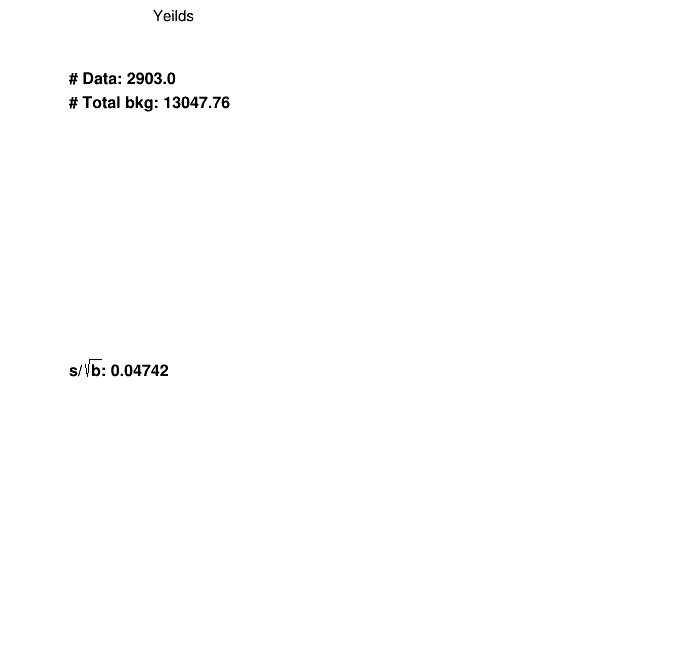

In [22]:
if DRAW_SR:
    region = "SR"

    with Pool() as p:
        p.starmap(wrapper_mp, list_variables) 
#     wrapper_mp('mass_pre', [45, 100, 1000, 'M_{ll} [GeV]'])

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)

array('f', [4.390909671783447, 4.866497039794922, 10.618252754211426, 117.42652893066406, 263.6268310546875, 2580.005859375, 2597.55126953125, 2638.5625, 2674.380859375, 2681.011962890625, 100.35910034179688, 5.417418956756592])
test


Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/SR/wotop/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/SR/wotop/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_pre.pdf has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/SR/wotop/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_lead_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/SR/wotop/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_lead_pre.pdf has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanv

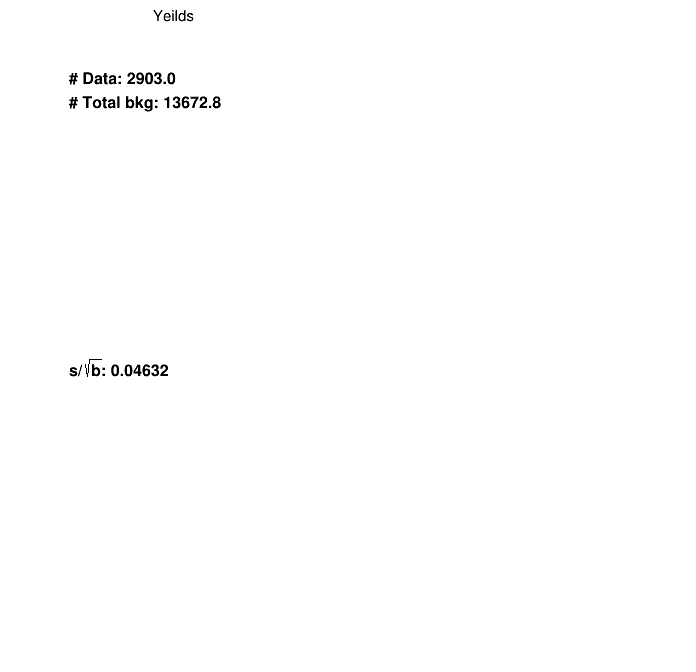

In [23]:
###### wotop ######
dic_variable={
    "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
    "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
    "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"], 
}
os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/wotop")

for variable, r in dic_variable.items():
    if not "Puppi" in variable:
        threshold = 0.3
    else:
        threshold = 0.5
    hist=HistStack(dic_df_raw, variable, "wotop", r[0], r[1], r[2], r[3])  
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/wotop/norm_"+query_str, blind_from=threshold) 
hist.get_yeilds()
hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/wotop/pie_"+query_str)  

In [24]:
dic_df_raw["TT"]["trigSF_pre"]

15       1.001046
16       0.997926
18       1.000533
27       0.992304
28       0.953071
           ...   
44978    1.000359
45094    0.997283
45125    0.998772
45149    0.998573
45157    0.979007
Name: trigSF_pre, Length: 75372, dtype: float32

# Signal Acc x Eff x presel

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/SR/sig_eff.pdf has been created


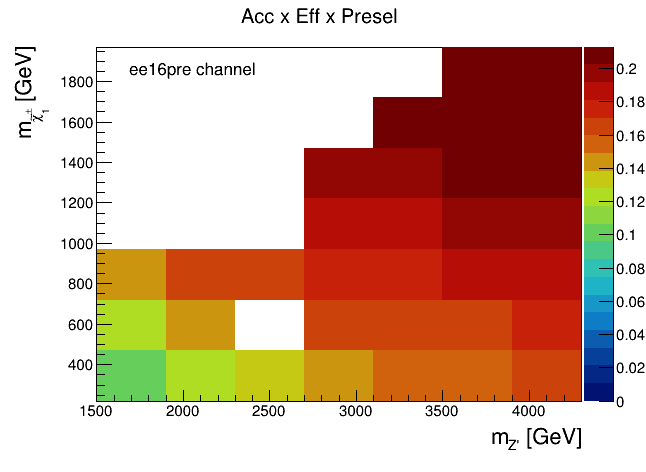

In [25]:
Zp_mass=[1700, 2100, 2500, 2900, 3300, 3700, 4100]
CH_mass=[345, 595, 845, 1095, 1345, 1595, 1845]
c1=rt.TCanvas("c1", "c1", 650, 500)
c1.SetLeftMargin(0.15)
c1.SetBottomMargin(0.15)
h2d1=rt.TH2D("h2d1", "", len(Zp_mass), Zp_mass[0]-200, Zp_mass[-1]+200, len(CH_mass), CH_mass[0]-125, CH_mass[-1]+125)
h2d1.SetTitle("Acc x Eff x Presel")

n_sig_in = 150000/4
if "em" in ERA:
    n_sig_in = 150000/2

for key in dic_df_raw:
    if not "Zp" in key:
        continue
    tmp=key.replace('_', '-')
    tmp=tmp.split('-')
    
    MZp=tmp[1]
    MCH=tmp[3]
    binx=Zp_mass.index(int(MZp))+1
    biny=CH_mass.index(int(MCH))+1
    h2d1.SetBinContent(binx, biny, dic_df_raw[key].shape[0]/(n_sig_in))
# # missing bin by hand
# h2d1.SetBinContent(5, 3, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000
# h2d1.SetBinContent(3, 4, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000

# set_palette("rainbow",255)
rt.gStyle.SetOptStat(0)
rt.gStyle.SetPalette(55)

h2d1.Draw("colz")
h2d1.SetYTitle("m_{#tilde#chi_{1}^{#pm}} [GeV]")
h2d1.SetXTitle("m_{Z'} [GeV]")
h2d1.GetYaxis().SetTitleSize(0.05)
h2d1.GetXaxis().SetTitleSize(0.05)
latex=rt.TLatex()
latex.DrawLatexNDC( 0.2,0.84, "#scale[0.8]{#font[42]{"+ERA+" channel}}")

c1.Draw()
c1.SaveAs(DATE+"/Presel/"+ERA+"/"+region+"/sig_eff.pdf")

# MET side band

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 6
DY1500To2000 : 315
DY2000To3000 : 69
DY500To700 : 270
DY700To800 : 162
DY800To1000 : 285
Zp-1700_CH-345 : 593
Zp-1700_CH-595 : 416
Zp-1700_CH-845 : 334
Zp-2100_CH-345 : 495
Zp-2100_CH-595 : 380
Zp-2100_CH-845 : 307
Zp-2500_CH-345 : 517
Zp-2500_CH-845 : 287
Zp-2900_CH-1095 : 212
Zp-2900_CH-1345 : 176
Zp-2900_CH-345 : 423
Zp-2900_CH-595 : 372
Zp-2900_CH-845 : 283
Zp-3300_CH-1095 : 205
Zp-3300_CH-1345 : 154
Zp-3300_CH-1595 : 166
Zp-3300_CH-345 : 405
Zp-3300_CH-595 : 308
Zp-3300_CH-845 : 266
Zp-3700_CH-1095 : 237
Zp-3700_CH-1345 : 162
Zp-3700_CH-1595 : 130
Zp-3700_CH-1845 : 124
Zp-3700_CH-345 : 368
Zp-3700_CH-595 : 303
Zp-3700_CH-845 : 266
Zp-4100_CH-1095 : 197
Zp-4100_CH-1345 : 140
Zp-4100_CH-1595 : 142
Zp-4100_CH-1845 : 117
Zp-4100_CH-345 : 344
Zp-4100_CH-595 : 294
Zp-4100_CH-845 : 254
TT : 38250
TThdampUp : 13551


        0.        , 18.9077373 , 16.49360596, 31.75827348, 13.48993157])}
{'puweightUp': array([3.90513615e+00, 2.01120157e+01, 7.38595581e-01, 8.73730017e+00,
       9.56587880e-01, 1.30030540e-01, 1.03095490e-01, 1.70497017e+00,
       3.46737838e-02, 0.00000000e+00, 1.30063917e-02, 1.54853793e-01,
       2.44302927e-03, 0.00000000e+00, 1.43196429e-03, 2.71732541e-03,
       4.00427651e-04, 3.96824617e-04, 8.10869238e-04, 0.00000000e+00,
       3.07177159e-04, 3.54721087e-03, 4.45792324e-05, 1.51991324e-03,
       3.06541822e-04, 1.62288454e-06, 1.16660245e-06, 3.65030975e-05,
       1.59485417e-07, 6.65827957e-04]), 'puweightDown': array([2.65422378e-01, 2.22881734e+01, 2.38659362e+00, 1.16370600e+01,
       1.11521395e+00, 2.01056424e-01, 1.30727696e-01, 1.82800339e+00,
       7.42838198e-02, 5.66369481e-04, 1.48786984e-02, 1.60332847e-01,
       3.92607550e-03, 5.71389977e-05, 5.89573484e-04, 2.17964892e-03,
       3.11320045e-04, 5.55750039e-04, 5.37936792e-04, 3.57149111e-06,
  

       7.12213886e-04, 2.63057416e-02])}{'puweightUp': array([2.16076694e+00, 1.84739615e+00, 2.23998270e+01, 5.20251684e+00,
       5.99141370e+00, 2.48775580e-02, 5.12891879e-01, 4.68858276e-01,
       4.25855679e-02, 1.29691974e+00, 6.71675275e-01, 1.10669315e-02,
       7.18000390e-02, 6.82140342e-01, 5.14763789e-04, 5.92665655e-03,
       8.56477764e-05, 3.78926432e-02, 2.93594037e-03, 6.41579285e-05,
       4.40755622e-05, 3.03946644e-06, 2.25453201e-04, 7.48407211e-04,
       3.10326311e-04, 7.17964233e-04, 2.18326482e-03, 1.45620550e-05,
       2.91694737e-07, 1.15822439e-04, 1.08042363e-03]), 'puweightDown': array([5.54504929e-01, 5.06901058e+00, 2.43334753e+01, 6.68316937e+00,
       2.69034865e+00, 1.05432342e-01, 8.87798529e-01, 4.70362540e-01,
       8.75633529e-02, 1.37887940e+00, 6.25571835e-01, 1.31316302e-02,
       6.51553354e-02, 5.80312320e-01, 1.05510676e-03, 7.36477676e-03,
       3.78057822e-04, 3.81381675e-02, 2.82873926e-03, 2.95648193e-04,
       5.38928086e-0

       5.50635332e-04, 8.22276187e-02, 3.52287443e-02])}

herehere  {'puweightUp': array([3.90513615e+00, 2.01120157e+01, 7.38595581e-01, 8.73730017e+00,
       9.56587880e-01, 1.30030540e-01, 1.03095490e-01, 1.70497017e+00,
       3.46737838e-02, 0.00000000e+00, 1.30063917e-02, 1.54853793e-01,
       2.44302927e-03, 0.00000000e+00, 1.43196429e-03, 2.71732541e-03,
       4.00427651e-04, 3.96824617e-04, 8.10869238e-04, 0.00000000e+00,
       3.07177159e-04, 3.54721087e-03, 4.45792324e-05, 1.51991324e-03,
       3.06541822e-04, 1.62288454e-06, 1.16660245e-06, 3.65030975e-05,
       1.59485417e-07, 6.65827957e-04]), 'puweightDown': array([2.65422378e-01, 2.22881734e+01, 2.38659362e+00, 1.16370600e+01,
       1.11521395e+00, 2.01056424e-01, 1.30727696e-01, 1.82800339e+00,
       7.42838198e-02, 5.66369481e-04, 1.48786984e-02, 1.60332847e-01,
       3.92607550e-03, 5.71389977e-05, 5.89573484e-04, 2.17964892e-03,
       3.11320045e-04, 5.55750039e-04, 5.37936792e-04, 3.57149111e-06,
       2

       7.12213886e-04, 2.63057416e-02])}
{'puweightUp': array([2.16076694e+00, 1.84739615e+00, 2.23998270e+01, 5.20251684e+00,
       5.99141370e+00, 2.48775580e-02, 5.12891879e-01, 4.68858276e-01,
       4.25855679e-02, 1.29691974e+00, 6.71675275e-01, 1.10669315e-02,
       7.18000390e-02, 6.82140342e-01, 5.14763789e-04, 5.92665655e-03,
       8.56477764e-05, 3.78926432e-02, 2.93594037e-03, 6.41579285e-05,
       4.40755622e-05, 3.03946644e-06, 2.25453201e-04, 7.48407211e-04,
       3.10326311e-04, 7.17964233e-04, 2.18326482e-03, 1.45620550e-05,
       2.91694737e-07, 1.15822439e-04, 1.08042363e-03]), 'puweightDown': array([5.54504929e-01, 5.06901058e+00, 2.43334753e+01, 6.68316937e+00,
       2.69034865e+00, 1.05432342e-01, 8.87798529e-01, 4.70362540e-01,
       8.75633529e-02, 1.37887940e+00, 6.25571835e-01, 1.31316302e-02,
       6.51553354e-02, 5.80312320e-01, 1.05510676e-03, 7.36477676e-03,
       3.78057822e-04, 3.81381675e-02, 2.82873926e-03, 2.95648193e-04,
       5.38928086e-

       5.50635332e-04, 8.22276187e-02, 3.52287443e-02])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUppuweightUp

hdampDownpuweightDown

PSUpl1prefiringUp

PSDownl1prefiringDown

puweightUpsum_upeffSFUp


puweightDownsum_down

l1prefiringUp['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
effSFDown
l1prefiringDown

topSFUpeffSFUp

effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUptopSFDown
PSDown

metUp
sum_up
metDown
sum_downtrigSFUp

['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']trigSFDown

hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
array('f', [1.4181872606277466, 1.428971290588379, 5.934500694274902, 70.18304443359375, 139.6707000732422, 1314.2158203125, 1367.2799072265625, 1398.923828125, 1392.95849609375, 1416.29736328125, 14

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/METSB/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_lead_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/METSB/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/METSB/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_lead_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/METSB/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and P

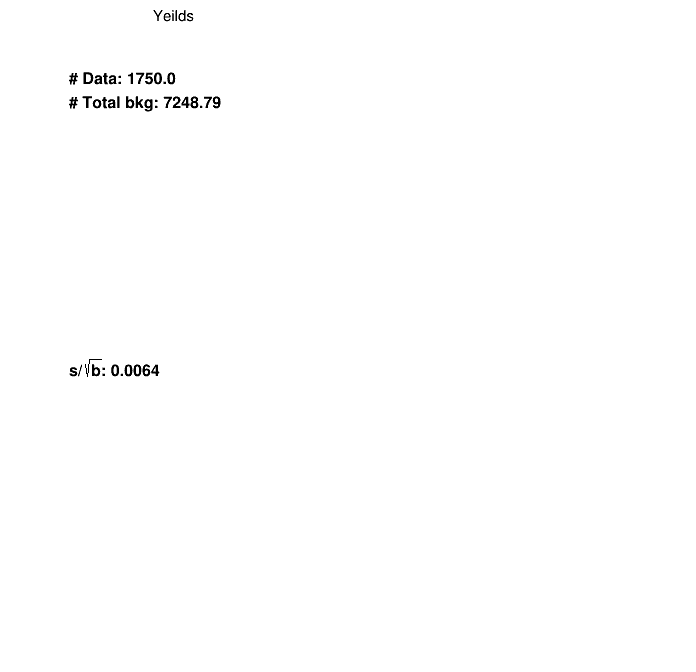

In [26]:
if RUN_SIDEBAND_MET:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp    
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    dic_variable={
        "PuppiMET_pre": [20, 0, 100, "Puppi p_{T}^{miss} [GeV]"],    
#         "MET_pre": [40, 0, 400, "p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
#         "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
    #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
    #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
    #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
    }
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "METSB"
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)        

In [27]:
if DUMP_SIDEBAND_MET_PKL:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_METSB.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# Mass side band

In [28]:
if RUN_SIDEBAND_MASS and not "em" in ERA:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    
    dic_variable={
        "PuppiMET_pre": [28, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
        "mass_pre": [1,80, 100, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
    }

    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "MASSSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "mass_pre", "weight", 1, 80,  100, "M_{ll} [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.get_yeilds()
    hist.create_root_file(file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB") 
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)
    
    sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF"] 
#     sys_list = ["puweight", "l1prefiring", "effSF", "topSF"] 
    for s in sys_list:
        hist=HistStack(dic_df_raw, "mass_pre", 'weight'+s+'Up', 1, 80,  100, "M_{ll} [GeV]")
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
        hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
        hist=HistStack(dic_df_raw, "mass_pre", 'weight'+s+'Down', 1, 80,  100, "M_{ll} [GeV]")
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
        hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
    hist=HistStack(dic_df_met_u_tmp, "mass_pre", 'weightmetUp', 1, 80,  100, "M_{ll} [GeV]")
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB") 
    hist=HistStack(dic_df_met_d_tmp, "mass_pre", 'weightmetDown', 1, 80,  100, "M_{ll} [GeV]")
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")      

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 0
DY1500To2000 : 0
DY2000To3000 : 0
DY500To700 : 0
DY700To800 : 0
DY800To1000 : 0
Zp-1700_CH-345 : 10
Zp-1700_CH-595 : 168
Zp-1700_CH-845 : 450
Zp-2100_CH-345 : 2
Zp-2100_CH-595 : 72
Zp-2100_CH-845 : 249
Zp-2500_CH-345 : 0
Zp-2500_CH-845 : 127
Zp-2900_CH-1095 : 142
Zp-2900_CH-1345 : 224
Zp-2900_CH-345 : 3
Zp-2900_CH-595 : 16
Zp-2900_CH-845 : 75
Zp-3300_CH-1095 : 117
Zp-3300_CH-1345 : 130
Zp-3300_CH-1595 : 157
Zp-3300_CH-345 : 2
Zp-3300_CH-595 : 6
Zp-3300_CH-845 : 57
Zp-3700_CH-1095 : 59
Zp-3700_CH-1345 : 85
Zp-3700_CH-1595 : 115
Zp-3700_CH-1845 : 164
Zp-3700_CH-345 : 2
Zp-3700_CH-595 : 5
Zp-3700_CH-845 : 31
Zp-4100_CH-1095 : 47
Zp-4100_CH-1345 : 69
Zp-4100_CH-1595 : 77
Zp-4100_CH-1845 : 112
Zp-4100_CH-345 : 0
Zp-4100_CH-595 : 2
Zp-4100_CH-845 : 18
TT : 18568
TThdampUp : 1257
TThdampDown : 1295
TTUp : 786
TTDown : 1

       3.29173377e-01, 4.87082757e-02, 8.91707139e-03, 6.74660678e-02])}
here {'puweightUp': array([1.66409347e+02, 3.24715419e+02, 1.98442680e-03, 1.47371791e-02,
       2.15662040e-01, 8.01154676e-03, 1.48617487e-02, 6.29183273e-02,
       3.99325285e-02, 2.18868112e-02, 2.86975219e-03, 7.16634317e-02,
       1.32049654e-02, 1.22977864e-03, 9.86971197e-03, 1.60175957e-03,
       6.77369210e-06, 8.55886224e-06, 5.05020440e-05, 7.74946718e-05,
       0.00000000e+00, 5.86413505e-04, 2.00167056e-05, 7.29347193e-03,
       7.58795476e-04, 2.08103640e-04, 7.12814351e-05, 1.90147581e-06]), 'puweightDown': array([1.99938990e+02, 3.84357434e+01, 2.34948184e-01, 1.02030459e-01,
       2.50356539e-01, 2.14088118e-02, 1.83738041e-02, 1.59377519e-01,
       4.59349949e-02, 3.33860825e-02, 3.09625199e-03, 5.56741800e-02,
       1.21563771e-02, 3.62771110e-06, 2.29485299e-03, 2.20412395e-03,
       2.71659242e-06, 4.38381825e-05, 1.30534118e-04, 1.93132437e-04,
       7.65015594e-05, 5.04381699e-04

       3.29173377e-01, 4.87082757e-02, 8.91707139e-03, 6.74660678e-02])}
{'puweightUp': array([916.45732627]), 'puweightDown': array([405.52733358]), 'l1prefiringUp': array([15.442978]), 'l1prefiringDown': array([16.17517538]), 'effSFUp': array([794.94414742]), 'effSFDown': array([751.16281951]), 'topSFUp': array([5.60682341]), 'topSFDown': array([0.]), 'metUp': array([1175.66967747]), 'metDown': array([684.23467631]), 'trigSFUp': array([7.58403034]), 'trigSFDown': array([9.16980628]), 'hdampUp': array([0]), 'hdampDown': array([122361.48959349]), 'PSUp': array([0]), 'PSDown': array([124416.17641489]), 'sum_up': array([53.99726829]), 'sum_down': array([498.64209191])}
here {'puweightUp': array([916.45732627]), 'puweightDown': array([405.52733358]), 'l1prefiringUp': array([15.442978]), 'l1prefiringDown': array([16.17517538]), 'effSFUp': array([794.94414742]), 'effSFDown': array([751.16281951]), 'topSFUp': array([5.60682341]), 'topSFDown': array([0.]), 'metUp': array([1175.66967747]), 'me

       0.00000000e+00, 0.00000000e+00])}
here {'puweightUp': array([2.24477507e+02, 1.70362772e+02, 2.41574618e+01, 1.26723199e+01,
       1.39163397e+00, 1.22815521e-04, 6.85450185e-01, 3.10607758e-01,
       2.77882142e-02, 4.65307849e-01, 3.75866323e-02, 1.77137419e-02,
       6.11841599e-03, 3.23326674e-02, 0.00000000e+00, 4.22387005e-04,
       6.14470409e-05, 8.93955860e-05, 7.30548682e-06, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 6.09266161e-09, 0.00000000e+00,
       6.60198872e-07, 7.79301889e-09, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'puweightDown': array([1.53970641e+02, 7.70958824e+01, 2.79815936e+00, 1.56482416e+01,
       7.43317452e-01, 2.03019103e-02, 7.28293674e-01, 2.68362359e-01,
       3.13164233e-02, 4.60751099e-01, 3.42121543e-02, 1.65836526e-02,
       2.26662770e-02, 5.10596499e-02, 1.03968843e-03, 4.03250775e-04,
       4.79842957e-05, 7.96037351e-05, 1.45723117e-05, 0.00000000e+00,
       0.00000000e+00, 0.00000

       0.00000000e+00, 0.00000000e+00])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
{'puweightUp': array([5.68075429e+00, 2.90301393e+02, 4.02170276e+00, 5.41807410e+00,
       2.13689868e+00, 5.10503428e-02, 7.02804328e-01, 2.28332689e+01,
       8.63392669e-02, 2.29219363e+00, 1.61112927e-01, 1.5

       2.17661837e-01, 3.80512949e-01, 9.71434948e-01])}
here {'puweightUp': array([5.68075429e+00, 2.90301393e+02, 4.02170276e+00, 5.41807410e+00,
       2.13689868e+00, 5.10503428e-02, 7.02804328e-01, 2.28332689e+01,
       8.63392669e-02, 2.29219363e+00, 1.61112927e-01, 1.54026378e-01,
       8.58154662e-03, 1.85684967e+00, 4.06756353e-01, 8.85528385e-02,
       5.50692803e-01, 7.45041023e-03, 5.37034781e-02, 1.44583535e-02,
       6.08802703e-03, 2.25153280e-01, 5.11513847e-02, 2.17786668e-02,
       1.60067606e-04, 3.94877873e-04, 3.67222076e-03, 7.27399873e-03,
       2.25883205e-04, 2.59398414e-04, 2.19778729e-03]), 'puweightDown': array([1.12810182e+01, 1.15644499e+02, 5.85268765e+00, 3.26960336e+00,
       2.42489172e+00, 1.98206477e-01, 2.55234647e-01, 1.35067617e-01,
       7.79314971e-02, 2.16429576e+00, 3.45185226e-01, 1.89999571e-01,
       2.83467430e-02, 2.56456346e+00, 2.76636342e-01, 1.35596350e-02,
       4.56827121e-01, 1.47989742e-02, 6.80748733e-02, 1.74608849e-02

       2.17661837e-01, 3.80512949e-01, 9.71434948e-01])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
array('f', [10.540047645568848, 32.18274688720703, 38.841705322265625, 9.827940940856934, 13.515048027038574, 379.55035400390625, 128.41990661621094, 116.03553771972656, 115.10734558105469, 123.26934051513672, 321.3490905761719, 0.0])
test


Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/MASSSB/sys/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/MASSSB/sys/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_mass_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/MASSSB/sys/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/MASSSB/sys/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_

In [29]:
if DUMP_SIDEBAND_MASS_PKL and not "em" in ERA:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_MASS.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# PT side band

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 0
DY1500To2000 : 42
DY2000To3000 : 5
DY500To700 : 38
DY700To800 : 36
DY800To1000 : 38
Zp-1700_CH-345 : 529
Zp-1700_CH-595 : 441
Zp-1700_CH-845 : 337
Zp-2100_CH-345 : 495
Zp-2100_CH-595 : 460
Zp-2100_CH-845 : 337
Zp-2500_CH-345 : 488
Zp-2500_CH-845 : 351
Zp-2900_CH-1095 : 258
Zp-2900_CH-1345 : 224
Zp-2900_CH-345 : 429
Zp-2900_CH-595 : 404
Zp-2900_CH-845 : 373
Zp-3300_CH-1095 : 268
Zp-3300_CH-1345 : 178
Zp-3300_CH-1595 : 180
Zp-3300_CH-345 : 371
Zp-3300_CH-595 : 402
Zp-3300_CH-845 : 315
Zp-3700_CH-1095 : 242
Zp-3700_CH-1345 : 190
Zp-3700_CH-1595 : 208
Zp-3700_CH-1845 : 174
Zp-3700_CH-345 : 363
Zp-3700_CH-595 : 348
Zp-3700_CH-845 : 307
Zp-4100_CH-1095 : 235
Zp-4100_CH-1345 : 198
Zp-4100_CH-1595 : 178
Zp-4100_CH-1845 : 156
Zp-4100_CH-345 : 384
Zp-4100_CH-595 : 319
Zp-4100_CH-845 : 266
TT : 25587
TThdampUp : 8526
TThdam

       3.89084314, 3.45783718, 2.06759619, 0.        , 0.        ])}
{'puweightUp': array([4.97653368e+01, 2.98840230e+01, 4.34914989e+00, 4.18327831e-02,
       4.01251189e-02, 1.26417531e-01, 8.60676261e-02, 1.32600661e-03,
       0.00000000e+00, 6.69204818e-04, 8.92106059e-06, 0.00000000e+00,
       0.00000000e+00, 6.57206800e-06, 4.94421082e-05]), 'puweightDown': array([6.98219666e+01, 3.34154097e+01, 3.52740216e+00, 1.28982597e-01,
       7.24132155e-02, 1.28077485e-01, 8.19873699e-02, 2.07443244e-03,
       1.04783686e-04, 1.57463975e-03, 9.21858286e-05, 7.44913003e-06,
       1.67014011e-06, 2.16479194e-05, 1.34577446e-04]), 'l1prefiringUp': array([9.52846954e+00, 1.80083769e+00, 2.58959644e-01, 5.14240077e-02,
       1.07285208e-02, 1.23818973e-03, 8.77423204e-04, 4.44206598e-05,
       4.89834096e-04, 1.40904275e-03, 3.77881502e-06, 2.23170451e-06,
       2.08437448e-08, 2.77983972e-06, 1.57056465e-07]), 'l1prefiringDown': array([1.01653374e+01, 1.93006133e+00, 2.78373202e-01,

        0.06485817,  0.20656842,  0.1503905 ,  0.28274466,  0.12740667])}
{'puweightUp': array([5.66364924e+01, 9.12926766e+00, 9.71963376e+00, 1.02134509e+01,
       1.79963060e-01, 1.43925073e-01, 3.65724394e-02, 3.57568634e-04,
       3.37595999e-05, 3.04954166e-06, 3.40996137e-09, 2.54718852e-05,
       1.25088727e-08, 5.52565651e-05, 0.00000000e+00, 6.68718282e-04,
       0.00000000e+00]), 'puweightDown': array([5.85054607e+01, 1.08188609e+01, 1.23940838e+01, 1.23405190e+01,
       6.57474161e-01, 2.94761063e-01, 4.28224819e-02, 4.68899560e-04,
       4.38559699e-05, 1.78949638e-05, 7.85720987e-09, 2.70827324e-05,
       1.57462413e-08, 9.72660631e-05, 0.00000000e+00, 4.59517184e-04,
       0.00000000e+00]), 'l1prefiringUp': array([4.04978697e+00, 6.56687820e-01, 9.87655164e-01, 9.29156611e-01,
       1.83333822e-01, 9.86247107e-03, 7.39019397e-03, 5.94412519e-05,
       2.09262777e-06, 1.51622960e-06, 9.70772936e-12, 1.03349582e-08,
       0.00000000e+00, 8.11359773e-08, 0.000000

       0.00000000e+00])}
{'puweightUp': array([0.00000000e+00, 5.44985599e-03, 1.25195906e-02, 7.93946849e-04,
       5.00271387e-01, 3.17645713e-01, 8.10441122e-01, 9.03198862e-01,
       4.95979427e-01, 9.63054721e-01, 2.96622340e+00, 2.74574701e+00,
       7.05529628e-01, 4.09567254e+00, 6.89875531e-01, 3.23709752e-01,
       4.89652100e-01, 1.71724887e-01, 2.12464054e-01, 2.00549038e-01,
       1.90470474e-01, 6.63205595e-02, 1.45912862e-03, 1.48837154e-03,
       2.43680137e-02, 5.88613133e-03, 3.16582479e-02]), 'puweightDown': array([0.00000000e+00, 5.07910523e-03, 4.06902489e-03, 1.78809770e-02,
       5.15944873e-01, 2.48848014e-01, 9.29841913e-01, 9.89735784e-01,
       6.03990027e-01, 1.41957367e+00, 3.69178658e+00, 3.61856800e+00,
       1.69974795e+00, 3.78872233e+00, 8.90339207e-01, 6.19383085e-01,
       6.72809164e-01, 1.59761826e-01, 2.41427967e-01, 1.82304214e-01,
       1.52178789e-01, 6.36597384e-02, 4.89353281e-03, 3.13252317e-03,
       2.64275343e-02, 3.70426786e-

       0.7573617 , 4.33327692])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']
{'puweightUp': array([0.1115993 , 0.76897793, 0.34120266, 0

...

        0.32340896,  0.26798029,  0.06098853,  0.18004472])}
{'puweightUp': array([0.        , 0.70541352, 0.51795535, 1.40480784, 1.50607563,
       4.56053572, 4.26045122, 7.91840904, 1.88947093, 0.72308935,
       1.19317775, 0.38900825, 1.06670515, 0.04584233, 0.        ]), 'puweightDown': array([0.        , 0.58937085, 0.58689536, 1.54911482, 2.12640058,
       5.83269009, 5.69885053, 9.71135408, 1.71069772, 1.50909596,
       1.50788286, 0.4597182 , 0.97958253, 0.07134299, 0.        ]), 'l1prefiringUp': array([0.        , 0.16088308, 0.08908207, 0.0288222 , 0.15174115,
       0.15048047, 0.33309362, 0.25635488, 0.33563871, 0.18375536,
       0.13562201, 0.03882549, 0.18466721, 0.45089458, 0.        ]), 'l1prefiringDown': array([0.        , 0.16013744, 0.0938002 , 0.03150928, 0.16659923,
       0.1675911 , 0.36988405, 0.28577588, 0.36380178, 0.20162471,
       0.14932887, 0.04146951, 0.18824379, 0.44489694, 0.        ]), 'effSFUp': array([ 0.        ,  0.56743332,  3.24423946,  3.

       0.00000000e+00, 0.00000000e+00])}
here {'puweightUp': array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 8.58367951e-05,
       4.24983321e-05, 4.34601008e-03, 9.87923116e-03, 1.54640538e-01,
       4.68699413e-02, 0.00000000e+00, 8.85446503e-01, 4.07545610e+00,
       7.11647728e+00, 6.44787572e+00, 2.93674851e+00, 5.24172094e+00,
       3.30545015e+00, 3.53965855e-01, 2.77830257e-01, 9.96832340e-02,
       2.73326552e-02, 2.37491092e-02, 2.96432143e-03, 2.73115219e-03,
       1.06280742e-04, 8.82714923e-05, 3.11883595e-06, 2.29062584e-05,
       0.00000000e+00, 0.00000000e+00]), 'puweightDown': array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 5.34768315e-05,
       6.56297900e-05, 1.81475367e-02, 5.56388087e-03, 2.83788028e-01,
       3.78209326e-02, 1.17496615e-02, 1.62100766e+00, 5.21725819e+00,
       8.85481642e+00, 7.34816959e+00, 3.15543943e+00, 5.60458745e+00,
       3.75321988e+00, 3.75735029e-01, 3.41798402e-01, 9.34322635e-02,
       1.74611141e-02, 2.56262

       0.00000000e+00, 0.00000000e+00])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
trigSFUppuweightUppuweightUp


trigSFDownpuweightDownpuweightDown


l1prefiringUp
hdampUppuweightUpl1prefiringUpl1prefiringDown



hdampDownpuweightDowneffSFUpl1prefiringDown



PSUpl1prefiringUpeffSFDowneffSFUp



l1prefiringDownPSDowntopSFUpeffSFDown



effSFUptopSFDownsum_up
topSFUp
effSFDown

trigSFUpsum_downtopSFDown



topSFUptrigSFDown['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']trigSFUp


topSFDownhdampUp
hdampDowntrigSFUp


PSUptrigSFDowntrigSFDown

PSDownhdampUp


sum_uphdampDownhdampUp


sum_downPSUphdampDown



['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']PSUp

PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']puweightUp

puweightDown
l1prefiringUp
PSDownl1prefiringDown

sum_upeffSFUppuweightUp

sum_downpuweightUp

effSFDown
puweightDown['puweight', 'l1p

        0.05498996,  0.25983982,  0.04323089,  0.24524742,  0.8596816 ])}
here {'puweightUp': array([0.00000000e+00, 0.00000000e+00, 1.13717512e+00, 9.54538858e+00,
       1.01254609e+01, 1.00529221e+01, 3.26775624e+00, 1.18323697e+00,
       2.10183803e+00, 3.04998470e-02, 3.04579021e-02, 1.59893167e-02,
       7.38723220e-02, 2.81899194e-03, 0.00000000e+00, 1.16093071e-02,
       3.06460761e-02, 5.21706243e-04, 1.80113013e-03, 0.00000000e+00,
       1.09297805e-03, 4.52096791e-03, 3.41291236e-04, 0.00000000e+00,
       8.27138124e-04]), 'puweightDown': array([0.00000000e+00, 0.00000000e+00, 1.49138938e+00, 1.24821959e+01,
       1.10974502e+01, 1.23538645e+01, 4.40293477e+00, 1.64345749e+00,
       2.20737700e+00, 9.69885450e-03, 3.76830153e-02, 2.07773781e-02,
       7.54944078e-02, 2.87878208e-03, 1.02090459e-03, 1.29603109e-02,
       3.00571055e-02, 9.29323133e-04, 1.82074377e-03, 8.74767568e-05,
       1.85427383e-03, 4.68573994e-03, 4.40304385e-04, 1.39344444e-04,
       1.6156

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas:

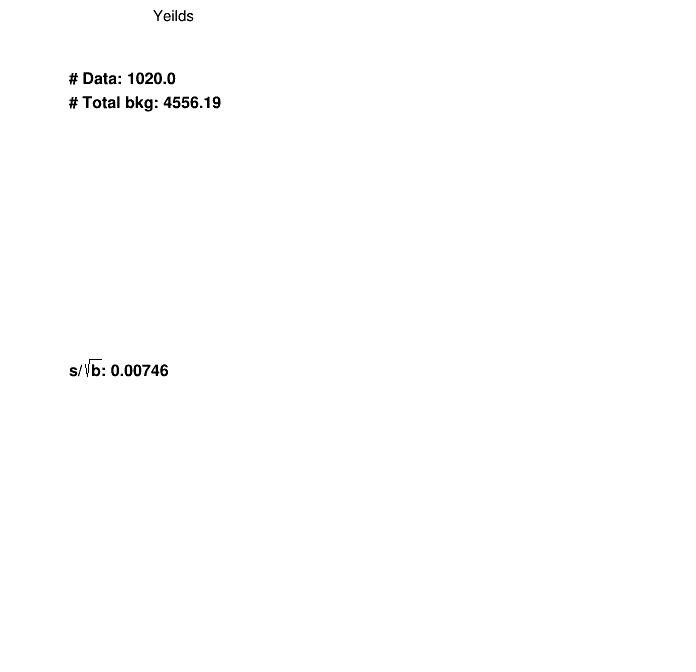

In [30]:
if RUN_SIDEBAND_PT:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre<40 and PuppiMET_pre>100"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp    
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    dic_variable={
        "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
#         "MET_pre": [40, 0, 400, "p_{T}^{miss} [GeV]"],    
        "mass_pre": [22, 100, 1000, "M_{ll} [GeV]"],
        "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [4, 0, 40, "p_{T}(l_{trail}) [GeV]"],
        "Zpt_pre": [25, 0, 500, "p_{T}(ll) [GeV]"],
        "MT_pre": [27, 0, 550, "M_{T} [GeV]"],
        "MT2_pre": [17, 0, 350, "M_{T2} [GeV]"],
        "U_pre": [14, 0, 660, "U [GeV]"],
        "JZB_pre": [14, 80, 660, "JZB"],
        "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
        "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
        "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
        "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
    #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
    #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
    #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
        "eta_lead_pre": [15, -3, 3, "#eta(l_{lead})"],
        "eta_trail_pre": [15, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
        "PuppiMET_phi_pre": [20, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
    }
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "PTSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "hdamp", "PS"]
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)        

In [31]:
if DUMP_SIDEBAND_PT_PKL:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_PT.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# b tag selection

In [32]:
if RUN_BTAG:
    dic_variable={
        "MET_pre": [25, 0, 500, "p_{T}^{miss} [GeV]"],    
#         "PuppiMET_pre": [50, 0, 500, "Puppi p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
#         "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
        "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"], 
        "nbjetflav_pre": [10, 0, 10, "N bjetflav"], 
#         "nbjet_pre": [10, 0, 10, "N bjet"], 
        "njet_pre": [10, 0, 10, "N jet"], 
#         "njet_l_pre": [9, 1, 10, "N  l jet"],     
#         "njet_c_pre": [9, 1, 10, "N  c jet"],     
#         "njet_b_pre": [9, 1, 10, "N  b jet"],    
#         "btagSF0_pre": [40, 0.9, 1.3, "B SF"],    
    }
    
#     base_line = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>80 and PuppiMET_pre>150 and MT_pre>130"
    base_line = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    dic_df_raw={}
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100 and njet_pre==1" #temp!
#     query_str=base_line+" and nbjetflav_pre==0" #temp!
    query_str=base_line #temp!

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)  
        print(key, ":", dic_df_raw[key].shape[0])

    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u
    nested_dic_df["met_d"]=dic_df_met_d
        
    sys_list = ["weight", "wobsf", "wotop"]
    for sys_key in sys_list:
        for variable, r in dic_variable.items():
            os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/Beq0/"+sys_key)
            hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
            c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/Beq0/"+sys_key+"/preselv1_"+query_str) 
    
#     hist=HistStack(dic_df_raw, "btagSF0_pre", "genweight_pre", 40, 0.9, 1.3, "B SF")            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/NONBTAG/"+sys_key+"/genweight_pre_preselv1_"+query_str, is_dnn=False) 

        #simply from last instance
        print(hist.get_yeilds())
        hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/Beq0/"+sys_key+"/pie_"+query_str)
        print(hist.nbin)    
    
#     with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_Beq0.pkl", "wb") as f:
#         pickle.dump(nested_dic_df, f)

# Export variables

In [33]:
if EXPORT_VARIABLE:
    # draw
    # get plot configuration
    dic_variable={
    #     "pt_trail_pre": [8, 40, 300, "p_{T}(l_{trail}) [GeV]"],
    #     "MT2_pre": [8, 0, 160, "M_{T2} [GeV]"],
        "H3PP_pre": [19, 95, 900, "H3PP [GeV]"],     
    }
    sys_src={
        "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre"]
    #     "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre", "topSF_pre"]
    }
    # sys_src=[]
    for key in dic_df_raw:
        if "Zp" in key:
            for variable, r in dic_variable.items():
                hist=HistStack(dic_df_raw, variable, sys_src, "presel", r[0], r[1], r[2], r[3])            
                c1=hist.draw_hist(key, ERA, ERA+"_exportdev"+query_str, True) 
                hist.create_root_file(key, variable, channel)
                hist.export_hist(key, variable, channel, "") 

    #simply from last instance
    print(hist.get_yeilds())
    hist.draw_pie()
    print(hist.nbin)
